# Causal & Probalistic Reasoning


# Introduction

## **Three forms of reasoning**

| Form | Starting point | Main question | Strength of conclusion |
|---|---|---|---|
| **Deduction** | A rule and a case | What must follow? | Necessary if the premises are true and the argument is valid |
| **Induction** | Repeated observations | What pattern is likely? | Probable, not guaranteed |
| **Abduction** | An observed effect | What could explain it? | A plausible or best explanation |

In [30]:
# Deduction: apply a rule to a case

'''
Rule: If an animal is a mammal, then it is warm-blooded.
Case: A whale is a mammal.
Conclusion: A whale is warm-blooded.
'''

rule = {"mammal": "warm-blooded"}
whale_facts = {"mammal"}

if "mammal" in whale_facts:
    whale_facts.add(rule["mammal"])

print("Facts derived for the whale:", sorted(whale_facts))

Facts derived for the whale: ['mammal', 'warm-blooded']


In [31]:
from itertools import product

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

In [32]:
# Induction: estimate a general pattern from observations

'''
Records whether each inspected product was acceptable
'''

quality_sample = np.array(
    [1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
     1, 0, 1, 1, 1, 1, 1, 1, 1, 1]
)

estimated_acceptance_rate = quality_sample.mean()
print(f"Observed products: {len(quality_sample)}")
print(f"Estimated acceptance rate: {estimated_acceptance_rate:.1%}")
print("This estimate is supported by the sample, but it is not logically guaranteed.")

Observed products: 20
Estimated acceptance rate: 90.0%
This estimate is supported by the sample, but it is not logically guaranteed.


In [33]:
# Abduction: rank explanations for an observed effect

'''
A wet street can be explained by rain or by a sprinkler.
Combines each explanation's prior probability with how well it predicts the evidence.
'''

explanations = pd.DataFrame(
    {
        "Hypothesis": ["Rain", "Sprinkler"],
        "Prior": [0.30, 0.20],
        "P(Wet street | Hypothesis)": [0.95, 0.80],
    }
)

explanations["Unnormalized score"] = (
    explanations["Prior"] * explanations["P(Wet street | Hypothesis)"]
)
explanations["Normalized plausibility"] = (
    explanations["Unnormalized score"]
    / explanations["Unnormalized score"].sum()
)


'''
The ranking produces a plausible explanation, not a logically certain cause.
Other hypotheses may have been omitted, and the assumed probabilities may be inaccurate.

'''
explanations.sort_values("Normalized plausibility", ascending=False)

,Hypothesis,Prior,P(Wet street | Hypothesis),Unnormalized score,Normalized plausibility
0,Rain,0.3000,0.9500,0.2850,0.6404
1,Sprinkler,0.2000,0.8000,0.1600,0.3596


## **Conditional Probability**

Conditional probability restricts attention to cases where the condition is true:

$$
P(A\mid B)=\frac{P(A\cap B)}{P(B)}, \qquad P(B)>0.
$$

The vertical bar is read as **“given.”** Therefore, $P(A\mid B)$ is read as “the probability of A given B.”

In [34]:
weather_data = pd.DataFrame(
    {
        "Day": range(1, 11),
        "Rain": [1, 0, 1, 0, 1, 0, 0, 1, 0, 1],
        "WetStreet": [1, 0, 1, 1, 1, 0, 0, 1, 1, 1],
    }
)

display(weather_data)

rain_and_wet = ((weather_data["Rain"] == 1) & (weather_data["WetStreet"] == 1)).mean()
wet = (weather_data["WetStreet"] == 1).mean()
rain_given_wet = rain_and_wet / wet

wet_given_rain = weather_data.loc[weather_data["Rain"] == 1, "WetStreet"].mean()

print(f"\nP(Rain ∩ WetStreet) = {rain_and_wet:.2f}")
print(f"P(WetStreet) = {wet:.2f}")
print(f"P(Rain | WetStreet) = {rain_given_wet:.3f}")
print(f"P(WetStreet | Rain) = {wet_given_rain:.3f}")
print("The two conditional probabilities are different.")

,Day,Rain,WetStreet
0,1,1,1
1,2,0,0
2,3,1,1
3,4,0,1
4,5,1,1
5,6,0,0
6,7,0,0
7,8,1,1
8,9,0,1
9,10,1,1



P(Rain ∩ WetStreet) = 0.50
P(WetStreet) = 0.70
P(Rain | WetStreet) = 0.714
P(WetStreet | Rain) = 1.000
The two conditional probabilities are different.


## **The Bayes Theorem**

For a hypothesis $H$ and evidence $E$:

$$
P(H\mid E)=\frac{P(E\mid H)P(H)}{P(E)}.
$$

For the two exhaustive cases $H$ and $\neg H$:

$$
P(E)=P(E\mid H)P(H)+P(E\mid\neg H)P(\neg H).
$$

A useful memory aid is:

$$
\text{Posterior}\propto\text{Likelihood}\times\text{Prior}.
$$

In [35]:
def bayes_binary(prior_h, likelihood_e_given_h, likelihood_e_given_not_h):
    """Compute P(H|E) và P(E)

    Parameters
    ----------
    prior_h : float -> P(H)
    likelihood_e_given_h : float -> P(E|H)
    likelihood_e_given_not_h : float -> P(E|¬H)
    """
    values = [prior_h, likelihood_e_given_h, likelihood_e_given_not_h]
    if not all(0 <= value <= 1 for value in values):
        raise ValueError("All probabilities must be between 0 and 1.")

    # Law of Total Probability
    evidence = (
        likelihood_e_given_h * prior_h
        + likelihood_e_given_not_h * (1 - prior_h)
    )
    if evidence == 0:
        raise ValueError("The evidence must have non-zero probability.")

    posterior = likelihood_e_given_h * prior_h / evidence
    return posterior, evidence


# Medical-test example

'''
- Disease prevalence: P(D)=0.01
- Sensitivity: P(+|D)=0.90
- False-positive rate: P(+|D^c)=0.05
A 90% sensitivity means that 90% of people who have the disease receive a positive result (TPs).
It does not mean that a person with a positive result has a 90% probability of disease.
'''

prevalence = 0.01
sensitivity = 0.90
false_positive_rate = 0.05

posterior_disease, evidence_positive = bayes_binary(
    prevalence,
    sensitivity,
    false_positive_rate,
)

print(f"P(+) = {evidence_positive:.4f}")
print(f"P(D | +) = {posterior_disease:.4f} = {posterior_disease:.1%}")

P(+) = 0.0585
P(D | +) = 0.1538 = 15.4%


In [36]:
# The same calculation using natural frequencies

population = 10_000
diseased = population * prevalence
not_diseased = population - diseased
true_positives = diseased * sensitivity
false_positives = not_diseased * false_positive_rate
all_positives = true_positives + false_positives

frequency_table = pd.DataFrame(
    {
        "Group": ["Disease", "No disease"],
        "People": [diseased, not_diseased],
        "Positive tests": [true_positives, false_positives],
    }
)
display(frequency_table)
print(f"Positive tests in total: {all_positives:.0f}")
print(f"Disease among positive tests: {true_positives:.0f}/{all_positives:.0f} = {true_positives/all_positives:.1%}")

,Group,People,Positive tests
0,Disease,100.0000,90.0000
1,No disease,9900.0000,495.0000


Positive tests in total: 585
Disease among positive tests: 90/585 = 15.4%


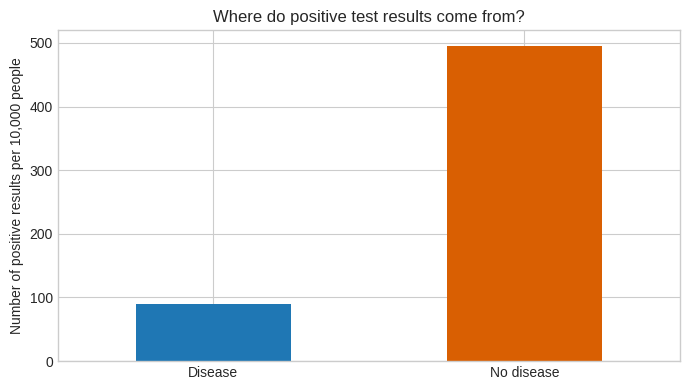

In [37]:
ax = frequency_table.set_index("Group")["Positive tests"].plot(
    kind="bar",
    color=["#1f77b4", "#d95f02"],
    figsize=(7, 4),
)
ax.set_title("Where do positive test results come from?")
ax.set_ylabel("Number of positive results per 10,000 people")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

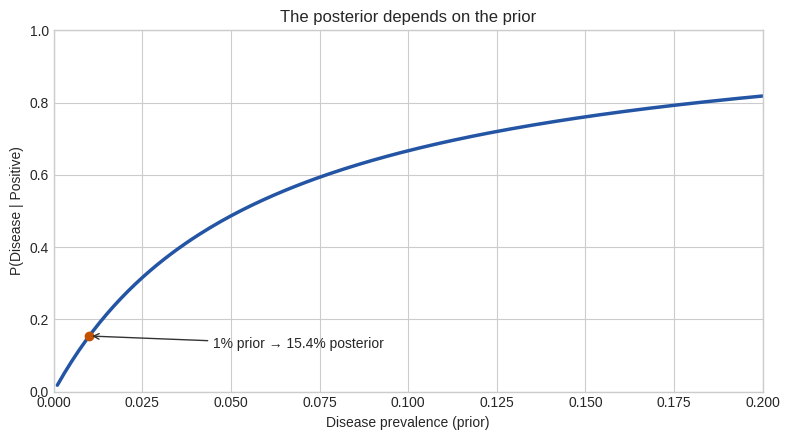

In [38]:
# How the prior changes the posterior

prevalence_grid = np.linspace(0.001, 0.20, 200)
posterior_grid = [
    bayes_binary(p, sensitivity, false_positive_rate)[0]
    for p in prevalence_grid
]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(prevalence_grid, posterior_grid, color="#2455a4", linewidth=2.5)
ax.scatter([prevalence], [posterior_disease], color="#c45100", zorder=3)
ax.annotate(
    f"1% prior → {posterior_disease:.1%} posterior",
    (prevalence, posterior_disease),
    xytext=(0.045, 0.12),
    arrowprops={"arrowstyle": "->", "color": "#333333"},
)
ax.set_xlabel("Disease prevalence (prior)")
ax.set_ylabel("P(Disease | Positive)")
ax.set_title("The posterior depends on the prior")
ax.set_xlim(0, 0.20)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

### **Bayesian Network**

A **Bayesian network** represents random variables and their probabilistic dependencies using a **directed acyclic graph (DAG)**.

We use the network:

$$
C\rightarrow S,\qquad C\rightarrow R,\qquad S\rightarrow W,\qquad R\rightarrow W,
$$

where $C$ = Cloudy, $S$ = Sprinkler, $R$ = Rain, and $W$ = Wet Grass.

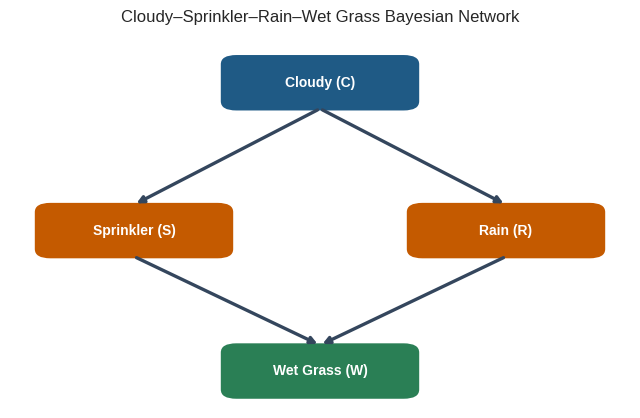

In [39]:
def draw_bayesian_network():
    """Draw a Directed Acyclic Graph."""
    from matplotlib.patches import FancyBboxPatch
    positions = {
        "Cloudy (C)": (0.50, 0.88),
        "Sprinkler (S)": (0.20, 0.48),
        "Rain (R)": (0.80, 0.48),
        "Wet Grass (W)": (0.50, 0.10),
    }
    colors = {
        "Cloudy (C)": "#1f5a85",
        "Sprinkler (S)": "#c45a00",
        "Rain (R)": "#c45a00",
        "Wet Grass (W)": "#2a7f55",
    }
    edges = [
        ("Cloudy (C)", "Sprinkler (S)"),
        ("Cloudy (C)", "Rain (R)"),
        ("Sprinkler (S)", "Wet Grass (W)"),
        ("Rain (R)", "Wet Grass (W)"),
    ]

    fig, ax = plt.subplots(figsize=(8, 4.8))
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")

    for source, target in edges:
        x1, y1 = positions[source]
        x2, y2 = positions[target]
        ax.annotate(
            "",
            xy=(x2, y2 + 0.07 if y2 < y1 else y2 - 0.07),
            xytext=(x1, y1 - 0.07 if y1 > y2 else y1 + 0.07),
            arrowprops={"arrowstyle": "-|>", "lw": 2.4, "color": "#34465d"},
        )

    for label, (x, y) in positions.items():
        box = FancyBboxPatch(
            (x - 0.14, y - 0.055),
            0.28,
            0.11,
            boxstyle="round,pad=0.02,rounding_size=0.025",
            facecolor=colors[label],
            edgecolor="none",
        )
        ax.add_patch(box)
        ax.text(x, y, label, color="white", ha="center", va="center", weight="bold")

    ax.set_title("Cloudy–Sprinkler–Rain–Wet Grass Bayesian Network", pad=12)
    plt.show()


draw_bayesian_network()

In [40]:
# Conditional probability tables (CPTs)

P_C_TRUE = 0.50
P_S_TRUE_GIVEN_C = {True: 0.10, False: 0.50}
P_R_TRUE_GIVEN_C = {True: 0.80, False: 0.20}
P_W_TRUE_GIVEN_SR = {
    (True, True): 0.99,
    (True, False): 0.90,
    (False, True): 0.90,
    (False, False): 0.00,
}

pd.DataFrame(
    [
        {"Sprinkler": s, "Rain": r, "P(WetGrass=True | S,R)": p}
        for (s, r), p in P_W_TRUE_GIVEN_SR.items()
    ]
)

,Sprinkler,Rain,"P(WetGrass=True | S,R)"
0,True,True,0.9900
1,True,False,0.9000
2,False,True,0.9000
3,False,False,0.0000


**Factorization of the joint distribution**

The DAG implies:

$$
P(C,S,R,W)=P(C)P(S\mid C)P(R\mid C)P(W\mid S,R).
$$

In [41]:
# Merge all the probability of values
def probability_of_value(value, probability_true):
    """Return P(X=value) knowing that P(X=True)."""
    return probability_true if value else 1 - probability_true


def joint_probability(c, s, r, w):
    """Find P(C=c, S=s, R=r, W=w) from four probability of values"""
    p_c = probability_of_value(c, P_C_TRUE)
    p_s = probability_of_value(s, P_S_TRUE_GIVEN_C[c])
    p_r = probability_of_value(r, P_R_TRUE_GIVEN_C[c])
    p_w = probability_of_value(w, P_W_TRUE_GIVEN_SR[(s, r)])
    return p_c * p_s * p_r * p_w


example_probability = joint_probability(True, False, True, True)
print("P(C=True, S=False, R=True, W=True) =", f"{example_probability:.4f}")

P(C=True, S=False, R=True, W=True) = 0.3240


In [42]:
# List all 2^4 = 16 joint probabilities and compute the sum

rows = []
for c, s, r, w in product([False, True], repeat=4):
    rows.append(
        {
            "C": c,
            "S": s,
            "R": r,
            "W": w,
            "Probability": joint_probability(c, s, r, w),
        }
    )

joint_table = pd.DataFrame(rows)
print(f"Sum of all joint probabilities: {joint_table['Probability'].sum():.6f}")
joint_table.head(8)

Sum of all joint probabilities: 1.000000


,C,S,R,W,Probability
0,False,False,False,False,0.2000
1,False,False,False,True,0.0000
2,False,False,True,False,0.0050
3,False,False,True,True,0.0450
4,False,True,False,False,0.0200
5,False,True,False,True,0.1800
6,False,True,True,False,0.0005
7,False,True,True,True,0.0495


In [43]:
# Exact inference by enumeration

'''When wet grass is observed, rain becomes more plausible.
 If the sprinkler is also known to be on, part of the evidence is already explained,
so the probability of rain decreases.
This is called explaining away.
'''


def exact_query(query, evidence=None):
    """Find P(query | evidence)

    Parameters
    ----------
    query : dict[str, bool]
    evidence : dict[str, bool] or None
    """
    evidence = evidence or {}

    def row_matches(row, assignments):
        """Kiểm tra một dòng có thỏa tất cả phép gán hay không."""
        return all(bool(row[name]) == value for name, value in assignments.items())

    denominator = joint_table.loc[
        joint_table.apply(lambda row: row_matches(row, evidence), axis=1),
        "Probability",
    ].sum()

    combined = {**evidence, **query}
    numerator = joint_table.loc[
        joint_table.apply(lambda row: row_matches(row, combined), axis=1),
        "Probability",
    ].sum()

    if denominator == 0:
        raise ValueError("The evidence has zero probability.")
    return numerator / denominator


queries = pd.DataFrame(
    [
        {
            "Question": "Predictive: P(W=True | C=True)",
            "Probability": exact_query({"W": True}, {"C": True}),
        },
        {
            "Question": "Diagnostic: P(R=True | W=True)",
            "Probability": exact_query({"R": True}, {"W": True}),
        },
        {
            "Question": "Intercausal: P(R=True | W=True, S=True)",
            "Probability": exact_query({"R": True}, {"W": True, "S": True}),
        },
    ]
)
queries

,Question,Probability
0,Predictive: P(W=True | C=True),0.7452
1,Diagnostic: P(R=True | W=True),0.7079
2,"Intercausal: P(R=True | W=True, S=True)",0.3204


In [44]:
# Conditional independence
p_s_and_r_given_c = exact_query({"S": True, "R": True}, {"C": True})
p_s_given_c = exact_query({"S": True}, {"C": True})
p_r_given_c = exact_query({"R": True}, {"C": True})

comparison = pd.DataFrame(
    {
        "Quantity": ["P(S=True, R=True | C=True)", "P(S=True | C=True) × P(R=True | C=True)"],
        "Value": [p_s_and_r_given_c, p_s_given_c * p_r_given_c],
    }
)

'''
The matching values demonstrate the network assumption 𝑆⊥𝑅∣𝐶
read as “Sprinkler is independent of Rain given Cloudy.”
'''


comparison

,Quantity,Value
0,"P(S=True, R=True | C=True)",0.0800
1,P(S=True | C=True) × P(R=True | C=True),0.0800


**A Bayesian network is not causal:** In an ordinary Bayesian network, an arrow  𝑋→𝑌  states that the distribution of  𝑌  directly depends on  𝑋  within the model. It does not, by itself, prove that changing  𝑋  will change  𝑌 .

A causal interpretation requires additional support, such as: *explicit causal assumptions; domain knowledge and a plausible temporal order; control of confounding variables; experimental or interventional evidence.*

**A Bayesian network is a DAG + conditional probability distributions**. A causal DAG adds a stronger causal meaning to its arrows.

## Part 1 — Reasoning and conditional probability

Consider a data set of production batches. `HighTemperature = 1` means that the batch was processed at a high temperature; `Defect = 1` means that a defect was observed.

In [45]:
# A data that observes temperature of production batches
batch_data = pd.DataFrame(
    {
        "Batch": range(1, 13),
        "HighTemperature": [1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0],
        "Defect": [1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0],
    }
)
batch_data

,Batch,HighTemperature,Defect
0,1,1,1
1,2,1,0
2,3,0,0
3,4,1,1
4,5,0,0
5,6,0,0
6,7,1,1
7,8,0,0
8,9,1,0
9,10,0,1


In [46]:
# Compute Empirical Probability
def empirical_probability(mask):
    """Return Boolean Mask"""
    return mask.mean()


p_high = empirical_probability(batch_data["HighTemperature"] == 1)
p_high_and_defect = empirical_probability(
    (batch_data["HighTemperature"] == 1) & (batch_data["Defect"] == 1)
)
p_defect_given_high = p_high_and_defect / p_high

print(f"P(HighTemperature) = {p_high:.3f}")
print(f"P(HighTemperature ∩ Defect) = {p_high_and_defect:.3f}")
print(f"P(Defect | HighTemperature) = {p_defect_given_high:.3f}")

P(HighTemperature) = 0.500
P(HighTemperature ∩ Defect) = 0.333
P(Defect | HighTemperature) = 0.667


The calculation uses

$$
P(\text{Defect}\mid\text{HighTemperature})=
\frac{P(\text{Defect}\cap\text{HighTemperature})}
     {P(\text{HighTemperature})}.
$$

Observing an association supports an **inductive** claim, but it does not prove that temperature causes defects. Other variables may explain the pattern.

Now use the same data set.

1. Calculate $P(\text{Defect})$, $P(\text{HighTemperature}\mid\text{Defect})$, and $P(\text{Defect}\mid\text{HighTemperature})$.
2. Explain in one or two sentences why the two conditional probabilities are different.
3. Classify each statement as **deduction**, **induction**, or **abduction**:
   - “Most observed high-temperature batches were defective, so future high-temperature batches may have a higher defect rate.”
   - “A defect was found; high temperature is one possible explanation.”
   - “All batches processed above the safety limit must be rejected; batch 8 exceeded the limit; therefore batch 8 must be rejected.”

In [47]:
p_defect = empirical_probability(batch_data["Defect"] == 1)
p_high_given_defect = p_high_and_defect / p_defect
p_defect_given_high_answer = p_high_and_defect / p_high

results_part1 = {
    "P(Defect)": p_defect,
    "P(HighTemperature | Defect)": p_high_given_defect,
    "P(Defect | HighTemperature)": p_defect_given_high_answer,
}
results_part1

{'P(Defect)': np.float64(0.4166666666666667),
 'P(HighTemperature | Defect)': np.float64(0.7999999999999999),
 'P(Defect | HighTemperature)': np.float64(0.6666666666666666)}

The two conditional probabilities $P(\text{HighTemperature} \mid \text{Defect})$ and $P(\text{Defect} \mid \text{HighTemperature})$ are different because they have different conditioning baselines (denominators):
- $P(\text{HighTemperature} \mid \text{Defect})$ answers: *"Out of all defective batches, how many were processed at a high temperature?"* (4 out of 5 batches, or 80.0%).
- $P(\text{Defect} \mid \text{HighTemperature})$ answers: *"Out of all high-temperature batches, how many developed defects?"* (4 out of 6 batches, or 66.7%).

- **Statement 1:** **Induction** (We generalized from specific historical observations about high-temperature batches to claim a broader pattern for future batches).
- **Statement 2:** **Abduction** (We observed an outcome—a defect—and proposed a plausible cause/hypothesis—high temperature—to explain it).
- **Statement 3:** **Deduction** (We applied a universal rule to a specific case to arrive at a logically certain, necessary conclusion).

## Part 2 — Bayes' theorem

A quality-control alarm detects faulty components.

- $P(F)=0.02$: 2% of components are faulty.
- $P(A\mid F)=0.95$: the alarm activates for 95% of faulty components.
- $P(A\mid\neg F)=0.04$: the alarm activates for 4% of non-faulty components.

We want $P(F\mid A)$, the probability that a component is faulty after the alarm activates.

In [48]:
def bayes_binary(prior_h, likelihood_e_given_h, likelihood_e_given_not_h):
    """Return P(E)and P(H|E)."""
    # Find P(E) from H and ¬H.
    evidence = (
        likelihood_e_given_h * prior_h
        + likelihood_e_given_not_h * (1 - prior_h)
    )
    posterior = likelihood_e_given_h * prior_h / evidence
    return evidence, posterior


p_fault = 0.02
p_alarm_given_fault = 0.95
p_alarm_given_not_fault = 0.04

p_alarm, p_fault_given_alarm = bayes_binary(
    p_fault,
    p_alarm_given_fault,
    p_alarm_given_not_fault,
)

print(f"Evidence P(Alarm) = {p_alarm:.4f}")
print(f"Posterior P(Fault | Alarm) = {p_fault_given_alarm:.4f} = {p_fault_given_alarm:.1%}")

Evidence P(Alarm) = 0.0582
Posterior P(Fault | Alarm) = 0.3265 = 32.6%


In [49]:
population = 10_000
faulty = population * p_fault
not_faulty = population - faulty
true_alarms = faulty * p_alarm_given_fault
false_alarms = not_faulty * p_alarm_given_not_fault

print(f"True alarms: {true_alarms:.0f}")
print(f"False alarms: {false_alarms:.0f}")
print(f"Faulty among all alarms: {true_alarms/(true_alarms + false_alarms):.1%}")

True alarms: 190
False alarms: 392
Faulty among all alarms: 32.6%


A medical test has the following properties: prevalence $P(D)=0.03$; sensitivity $P(+\mid D)=0.92$; specificity $P(-\mid\neg D)=0.96$.

1. Calculate the false-positive rate, $P(+)$, and $P(D\mid +)$.
2. Use a population of 10,000 people to show the numbers of true positives and false positives. Confirm the posterior using natural frequencies.
3. Recalculate $P(D\mid +)$ when prevalence increases from 3% to 10%. Explain the effect of the prior.

In [50]:
prevalence = 0.03
sensitivity = 0.92
specificity = 0.96

# Compute the three values
false_positive_rate = 1 - specificity
p_positive = sensitivity * prevalence + false_positive_rate * (1 - prevalence)
p_disease_given_positive = sensitivity * prevalence / p_positive

{
    "False-positive rate": false_positive_rate,
    "P(Positive)": p_positive,
    "P(Disease | Positive)": p_disease_given_positive,
}

{'False-positive rate': 0.040000000000000036,
 'P(Positive)': 0.06640000000000004,
 'P(Disease | Positive)': 0.41566265060240937}

In [51]:
population = 10_000
number_with_disease = population * p_disease_given_positive
number_without_disease = population - number_with_disease
true_positives = number_with_disease * sensitivity
false_positives = number_without_disease * false_positive_rate
posterior_from_counts = true_positives / (true_positives + false_positives)

{
    "People with disease": number_with_disease,
    "People without disease": number_without_disease,
    "True positives": true_positives,
    "False positives": false_positives,
    "Posterior from counts": posterior_from_counts,
}

{'People with disease': 4156.626506024094,
 'People without disease': 5843.373493975906,
 'True positives': 3824.0963855421664,
 'False positives': 233.73493975903645,
 'Posterior from counts': 0.942399049881235}

In [52]:
# Use bayes_binary with prior mới = 0.10 (10%).
posterior_with_10_percent_prior = bayes_binary(
    0.10,
    p_disease_given_positive,
    false_positive_rate,
)[1]
posterior_with_10_percent_prior

0.5358807082945011

The posterior probability $P(D \mid +)$ depends heavily on the **prior probability (prevalence)** of the disease, according to Bayes' Theorem:

$$
P(D \mid +) = \frac{P(+ \mid D)P(D)}{P(+)}
$$

Even though the test's sensitivity and specificity remain fixed, the base rate of the disease dictates the proportion of true positives to false positives in the population:
- When the disease is extremely rare (e.g., $3\%$ prevalence), most positive test results are actually false positives generated by the healthy majority ($97\%$ of the population).
- When prevalence increases to $10\%$, the absolute number of sick people increases, causing true positives to dominate the total pool of positive tests. Consequently, the posterior probability $P(D \mid +)$ increases from $41.6\%$ to $53.6\%$, demonstrating that a positive result on a rare condition is less conclusive than on a more common one.

## Part 3 — Bayesian network inference

We reuse the Cloudy–Sprinkler–Rain–Wet Grass network:

$$
C\rightarrow S,\qquad C\rightarrow R,\qquad S\rightarrow W,\qquad R\rightarrow W.
$$

Step 1 defines the conditional probability tables. Every table stores the probability that its variable is `True`.

In [53]:
# Declare the conditional table for the sample Bayes.
P_C_TRUE = 0.50
P_S_TRUE_GIVEN_C = {True: 0.10, False: 0.50}
P_R_TRUE_GIVEN_C = {True: 0.80, False: 0.20}
P_W_TRUE_GIVEN_SR = {
    (True, True): 0.99,
    (True, False): 0.90,
    (False, True): 0.90,
    (False, False): 0.00,
}

Step 2 uses the factorization

$$
P(C,S,R,W)=P(C)P(S\mid C)P(R\mid C)P(W\mid S,R).
$$

In [54]:
def probability_of_value(value, probability_true):
    """Return P(X=value) from probability P(X=True)."""
    return probability_true if value else 1 - probability_true


def joint_probability(c, s, r, w):
    """Return probability for C, S, R and W."""
    p_c = probability_of_value(c, P_C_TRUE)
    p_s = probability_of_value(s, P_S_TRUE_GIVEN_C[c])
    p_r = probability_of_value(r, P_R_TRUE_GIVEN_C[c])
    p_w = probability_of_value(w, P_W_TRUE_GIVEN_SR[(s, r)])
    return p_c * p_s * p_r * p_w


example = joint_probability(c=True, s=False, r=True, w=True)
print(f"P(C=True,S=False,R=True,W=True) = {example:.4f}")

P(C=True,S=False,R=True,W=True) = 0.3240


Step 3 enumerates all 16 states. A valid joint distribution must sum to 1.

In [55]:
guided_rows = []
for c, s, r, w in product([False, True], repeat=4):
    guided_rows.append(
        {
            "C": c,
            "S": s,
            "R": r,
            "W": w,
            "Probability": joint_probability(c, s, r, w),
        }
    )

guided_joint_table = pd.DataFrame(guided_rows)
print(f"Number of states: {len(guided_joint_table)}")
print(f"Probability sum: {guided_joint_table['Probability'].sum():.6f}")
guided_joint_table.head()

Number of states: 16
Probability sum: 1.000000


,C,S,R,W,Probability
0,False,False,False,False,0.2000
1,False,False,False,True,0.0000
2,False,False,True,False,0.0050
3,False,False,True,True,0.0450
4,False,True,False,False,0.0200


Step 4 demonstrates marginalization. To calculate $P(W)$, sum the probabilities of all rows where $W$ is true. The remaining variables are hidden and are eliminated by summation.

In [56]:
p_wet_grass = guided_joint_table.loc[
    guided_joint_table["W"], "Probability"
].sum()
print(f"P(W=True) = {p_wet_grass:.4f}")

P(W=True) = 0.6471




1. Complete `enumerate_joint()` and verify that its 16 probabilities sum to 1.
2. Complete `exact_query()` to calculate $P(\text{query}\mid\text{evidence})$ by filtering and summing the joint table.
3. Calculate and interpret:
   - predictive inference: $P(W\mid C)$;
   - diagnostic inference: $P(R\mid W)$;
   - intercausal inference: $P(R\mid W,S)$.
   Explain **explaining away** by comparing the last two values.

In [57]:
def enumerate_joint():
    rows = []
    for c, s, r, w in product([False, True], repeat=4):
      rows.append(
        {
            "C": c,
            "S": s,
            "R": r,
            "W": w,
            "Probability": joint_probability(c, s, r, w),
        }
    )
    # Add C, S, R, W and Probability to rows.
    return pd.DataFrame(rows)


student_joint_table = enumerate_joint()
if student_joint_table.empty:
    print("Not Implemented")
else:
    print(f"Rows: {len(student_joint_table)}")
    print(f"Probability sum: {student_joint_table['Probability'].sum():.6f}")

Rows: 16
Probability sum: 1.000000


In [58]:
def exact_query(query, evidence, joint_table):
    """Return P(query | evidence).

    Parameters
    ----------
    query : dict[str, bool]
    evidence : dict[str, bool]
    joint_table : pandas.DataFrame
    """
    # 1. Filter evidence to find numerator
    # 2. Filter all satisfy evidence and query to compute enominator
    # 3. Return numerator / denominator.
    numerator = joint_table.loc[
        (joint_table[list(evidence.keys())] == pd.Series(evidence)).all(axis=1),
        "Probability",
    ].sum()

    denominator = joint_table.loc[
        (joint_table[list(query.keys())] == pd.Series(query)).all(axis=1),
        "Probability",
    ].sum()

    return numerator / denominator

    return None

In [59]:
if student_joint_table.empty:
    print("Not Implemented.")
else:
    p_w_given_c = exact_query({"W": True}, {"C": True}, student_joint_table)
    p_r_given_w = exact_query({"R": True}, {"W": True}, student_joint_table)
    p_r_given_w_s = exact_query(
        {"R": True},
        {"W": True, "S": True},
        student_joint_table,
    )
    print("P(W=True | C=True) =", p_w_given_c)
    print("P(R=True | W=True) =", p_r_given_w)
    print("P(R=True | W=True, S=True) =", p_r_given_w_s)

P(W=True | C=True) = 0.7726781023025806
P(R=True | W=True) = 1.2942000000000002
P(R=True | W=True, S=True) = 0.5562000000000001


Learning that the sprinkler is on **lowers** the probability of rain after wet grass has already been observed. This is a classic example of **"explaining away"** (intercausal reasoning):
- Initially, seeing that the grass is wet ($W=True$) strongly increases our belief in both possible causes: Rain ($R$) and Sprinkler ($S$).
- However, once we observe that the Sprinkler is indeed active ($S=True$), we find a fully sufficient explanation for the wet grass. This "explains away" the observation, making the alternative cause (Rain) less necessary to assume, which reduces $P(R=True \mid W=True, S=True)$ compared to $P(R=True \mid W=True)$.

### **Causal caution:**

The arrows in a Bayesian network do not automatically prove that the variables are causally related. Mathematically, a Bayesian network only represents factorization and conditional independence (probabilistic dependencies). To interpret arrows as actual physical causes, we must make additional assumptions (such as Causal Sufficiency, Causal Markov Condition, and Faithfulness) and ideally back them up with experimental data (e.g., randomized controlled trials or direct interventions).